<a href="https://colab.research.google.com/github/LiaIssakov/Portfolio_2025/blob/main/Lia_Issakov_HW4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 4 (The Big One)
> With improvements by Gavin Sidhu (Fall 2023)
# Lin. Alg. for Data Science.
# Due date: hopefully a reasonable one, see discord/canvas

# Collaboration rules:
> For this task, I'd prefer if you worked on your own. But **if you run into time-consuming technical difficulties** (with Python, numpy, matplotlib) -- feel free to ask for help on discord. Just don't post your code so that you don't spoil anything (especially conceptual).

> There are two parts which you can freely discuss on Discord and share code (finding nearest vectors and plotting tiny images).

> You can also reuse code from our past notebooks, and check documentation for the libraries, python etc. However, all new code ought to be conceptualized and written by you. In particular, using LLMs to solve any part of the assignment is *not* considered fair game.

# Submission Instructions:
0. Solve the tasks (by writing Python code).
1. Prefix the name of the notebook with your name (e.g. Who_Ever_HW4.ipynb)
2. Run all the cells in the notebook, so that all results are visible.

3. Important: on colab create a shared link using the option **"for anyone with the link"** and switch permission from **Viewer** to **Editor**, so that it says "Anyone on the internet with the link can edit".

4. Submit the above link on canvas before the deadline. Do not modify the notebook after that.

5. The day after the final deadline, **you will be required to answer** some brief questions about your solution via a google form I will send you. This is part of the homework assignment!

> This time I will also ask you to copy-paste some of your answers below from this notebook to the form. I know it's annoying, but it'll speed up the grading.





# Instruction specific to this assignment (READ!)
- **You are encouraged to** use the code from our previous notebooks (but do make an effort to understand what is does, don't just copy-paste blindly)

- **You MUST NOT** use any language and library elements that were not covered in class colabs. If you feel you absolutely must use something else, contact me.

> Rationale: First, while class attendence is not mandatory, I want you to be familiar with class notebooks. Second, this requirement simulates a situation in which you need to get proficient with in-house software tools developed by your company. Also, this should discourage *some* of you from blindly using LLMs, which unfortunately has been happenning. (Most of you don't do this so it's annoying -- but I suppose you don't necessarily want to share your hard-earned A with someone who just chatGPT-ed their way through their education...)

- Tasks (**marked T:**) require you to do some coding (usually in the code cell directly below).

- Questions (**marked Q:**) require you to briefly answer some questions in text. Make sure the answers highlight your understanding of the: mathematics, algorithms, important insights from data visualizations etc.

For clarity, **please answer each question like this** directly below the question (and not as a comment in the code.):

> **A**:


# Goals Overview

The **objective** of this notebook is to **explore and analyze** a realistic image dataset called cifar100, which contains 60,000 color images.

So it's more about your understanding what's happening in this data through the lens of specific methods, rather than just writing some code.

Due to the dataset's size, manually examining each image is impractical. Instead, we will use t-SNE and kMeans and also investigate nearest neighbors using the Euclidean metric.

Previously, our focus was mostly on MNIST, which contains real data but is heavily preprocessed and idealized for our use. Now, our goals are to:

- Evaluate the performance of t-SNE, kMeans, and kNN when applied to more realistic images
- Identify patterns in the images, their tSNE embeddings and k-means clusters and nearest neighbours -- and explain why they occur.
- Recognize the limitations of these methods.

Our main operations will involve working with high-dimensional vectors, norms, distances, sums, and means.

There will be four main parts in this notebook:

1. Loading the data and checking its format is correct for our use
2. Preparing a function for identifying nearest neighbors
3. Conducting exploratory data analysis with t-SNE (with an extra step using nearest neighbor search)
4. Performing data analysis by clustering with kMeans (using insights from the previous part)

There is also be a bonus section where you can upload your own image and look at similar images!


# Guidelines
- Follow the assigned tasks in a reasonable manner
- Note that this is one big assignment focusing on data analysis, not many isolated tasks.
- You will likely need to do **several iterations** on this assignment. It's a good idea to start from a reasonably small subset of the data just to make sure everything works.
- Provide **brief yet informative answers** to the questions. Elaborate when necessary, but be concise.
- Make sure your plots, visualizations, and other outputs are clean and informative.

- This is a large assignment focusing on data analysis. The point below are important, but not as crucial:
    * Writing efficient code (although it might test your patience if it's too slow)
    * Ensuring code readability (it will make life easier, though)
    * Including comments (but they might help when you have to fill out the form)

- Do consider defining functions for repetitive tasks, like finding nearest neighbors (it'll make your life much easier)

- Do make sure you use the appropriate tool for each task -- and that your use it correctly.

**Note:** This is a substantial assignment, and while coding details won't be nitpicked at during grading, prioritizing clarity where possible will *probably* enhance your overall experience. Same for efficiency.

**Another note:** I use the term plot loosly. It can mean plt.plot, scatter, imshow etc.



# Imports

**T:** Import the things you need -- and nothing else!

> Hopefully this will make sure that you didn't just copy-paste all the imports from all my previous notebooks.

In [50]:
from keras.datasets import cifar100 # this will get you the data!
import matplotlib.pyplot as plt
import numpy as np
from sklearn.manifold import TSNE
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from sklearn.cluster import MiniBatchKMeans

# The data

> CIFAR-100 is another classical image dataset. We have experience with using MNIST, and the format will be quite similar. Each image is 32x32, with 3 color values (R,G,B) for each pixel ranging from 0-255.

## Load the data (like we did with MNIST)

> Recall that mnist.load_data() returned two pairs:
(train_images, train_labels), (test_images, test_labels).
 We will mostly use train_images, and train_labels at one occasion. It works similarly for the CIFAR-100 dataset imported above.

In [51]:
!mkdir -p ~/.keras/datasets
!wget -O ~/.keras/datasets/cifar-100-python-target_archive \
    https://data.brainchip.com/dataset-mirror/cifar100/cifar-100-python.tar.gz

(train_images, train_labels), (test_images, test_labels) = cifar100.load_data()

--2026-11-11 23:05:40--  https://data.brainchip.com/dataset-mirror/cifar100/cifar-100-python.tar.gz
Resolving data.brainchip.com (data.brainchip.com)... 146.59.209.152, 2001:41d0:301::31
Connecting to data.brainchip.com (data.brainchip.com)|146.59.209.152|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 169001437 (161M) [application/x-gzip]
Saving to: ‘/root/.keras/datasets/cifar-100-python-target_archive’

/root/.keras/datase 100%[===================>] 161.17M  13.8MB/s    in 12s     

2026-11-11 23:05:53 (13.4 MB/s) - ‘/root/.keras/datasets/cifar-100-python-target_archive’ saved [169001437/169001437]



> To avoid problems later, ensure they are float values between 0 and 1.
 Be sure to not re-run the code for doing this without first re-initializing the data using the above code, otherwise you may accidentally scale the data down even further.

> Double check the shape of the arrays you loaded. Also ensure you have normalized the R,G,B values to between 0 and 1.

In [52]:
train_images = train_images.astype('float32') / 255.0
test_images = test_images.astype('float32') / 255.0

In [53]:
assert train_images.shape[1:] == (32, 32, 3)
assert test_images.shape[1:] == (32, 32, 3)

assert train_images.min() >= 0.0 and train_images.max() <= 1.0
assert test_images.min() >= 0.0 and test_images.max() <= 1.0

> Plot the image with the index defined below. Hint: use plt.imshow and not plt.plot!

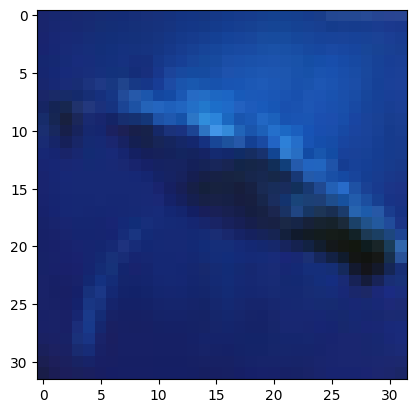

In [54]:
ind = 4311

plt.imshow(train_images[ind])

## Channels of an RGB image

> An image has 3 channels corresponding to R,G,B.

**T:** Plot each channel (of the image you plotted) separately using plt.imshow. Then look at the 3 plots. Which channel (R,G,B) contributes the most (has highest intensity values)?

> Hint: You'll likely use a syntax similar to how we selected the columns of a 2D array.

**Q:** Is the result consistent with your expectation based on eyeballing the original image?

> **Answer**: Yes, the result is consistent with my expectation. The blue channel contributes the most as the image is mostly blue, there is also some green.

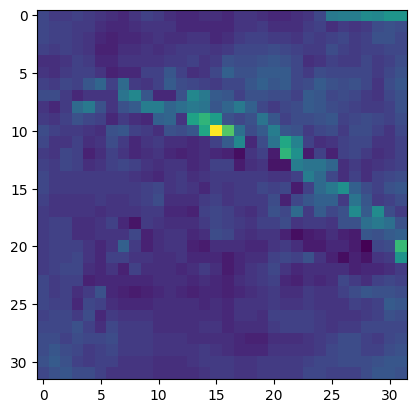

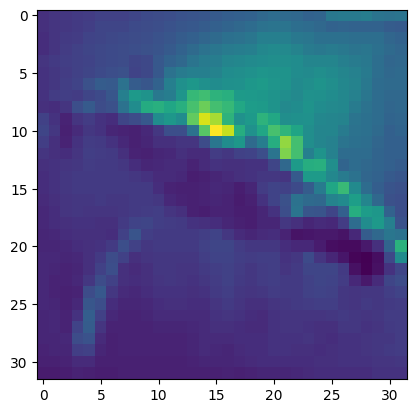

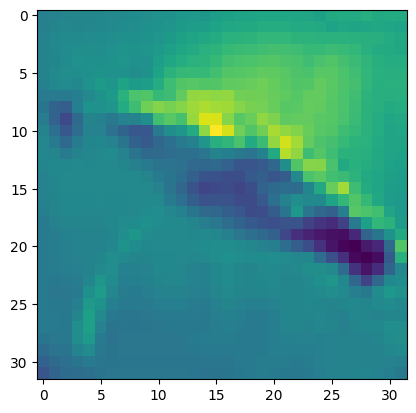

In [55]:
for i in range(3):
  plt.imshow(train_images[ind][:, :, i])
  plt.show()

# Closest images

> Recall that we can think about an image as a vector in a high-dimensional vector space, $\mathbb{R}^d$.

**T:** Write a **Python function** which returns the $k$ nearest vectors (or in this case, the $k$ nearest images) using the Euclidean distance.

> Tip: Try to use np.argsort for efficient sorting -- it's very useful whenever we talk about finding k nearest vectors. It may be convenient to have one function returning the indices, and another returning the actual images (perhaps using the previous function).

> If you get stuck here, search the colabs and feel free to ask for help on Discord -- that's okay, it's not the point of this assignment.

**T:** Test this function briefly, so that you're sure it works.

> Simple unit tests (using asserts) are enough.

**T:** Compute and plot a bunch of images closest to the above image. For clarity, plot the images in a horizontal row.

> As a gesture of good faith, below is a helpful function I wrote *especially* for you!



In [56]:
def plot_images_in_a_row(ims):
  'Takes a list/array of images and plots them spaced horizontally.'
  _, axs = plt.subplots(1, len(ims), figsize=(20,5))
  for im, ax in zip(ims, axs.ravel()):
    ax.imshow(im)
    ax.axis('off')

In [57]:
train_images_reshaped = train_images.reshape(train_images.shape[0], -1)

In [58]:
def nearest_vectors(image_ind, k_nearest):
  '''Finds the k nearest images to a specified image using Euclidean distance.

  Args:
    image_ind (int): The index of the image in train_images to be used as
      the query image
    k_nearest (int): The number of nearest images to return

  Returns:
    Images with the smallest distances, including the original image.
  '''
  query_vector = train_images[image_ind].reshape(1, -1)
  distances = np.sqrt(np.sum((train_images_reshaped - query_vector) ** 2, axis=1))
  sorted_inds = np.argsort(distances)
  k_inds = sorted_inds[:k_nearest]

  return [train_images[i] for i in k_inds]

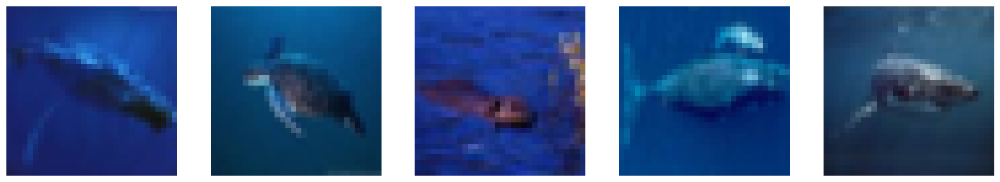

In [59]:
test = nearest_vectors(ind, k_nearest=5)
plot_images_in_a_row(test)

# Explatory data analysis with t-SNE


**T:** Set up t-SNE with appropriate parameters.

> Tip: Use the "random_state" parameter in the TSNE function to ensure you get the same results if you have to re-run the notebook!

**T:** Make sure there are *no warnings* printed (you may need to set some additional parameters, but perhaps not).

In [60]:
num_iters = 1000
perplexity = 25
my_random_state = 1236
tsne = TSNE(n_components=2, max_iter=num_iters,
            perplexity=perplexity, random_state=my_random_state)

**T:** Fit the model with your data and retreive the result. (Remember that t-SNE doesn't know -- or care -- about 2D images)

> Hint: You may need to limit the amount of data, since t-SNE tends to be slow. You could even work with a small subset and increase it to a larger subset for the final result. Try to be smart about it, otherwise you'll wait forever for t-SNE to finish!

> Fun fact: Even disregarding the dimension of the space, performing t-SNE (without extra optimizations) on  $n$ data points has the time complexity of $\Omega(n^2)$, so you can see why starting with a small subset may be a good idea!

> Overall, you may lose a lot of time if you recompute all the notebook on too large data. You may start small and quick, and rerun on larger data once things work.

In [61]:
subset_size = 5000
X_subset = train_images_reshaped[:subset_size]
X_reduced = tsne.fit_transform(X_subset)

In [62]:
assert X_reduced.shape == (5000, 2)

## Plotting t-SNE embedding

**T:** Scatter-plot the output of t-SNE.

**Q:** Did it work? Can you see any significant structure? Maybe some groups? If so where are they on the plot (mention coordinates).

> **A:** Yes, it worked. The plot shows a 'blob' of points. I think the most significant structure is between 5 and 30 on the x-axis and 25 and 40 on the y-axis. This section branches off of the blob. I think the right edge of the 'blob' also seems to branch off a little from the rest of the points.


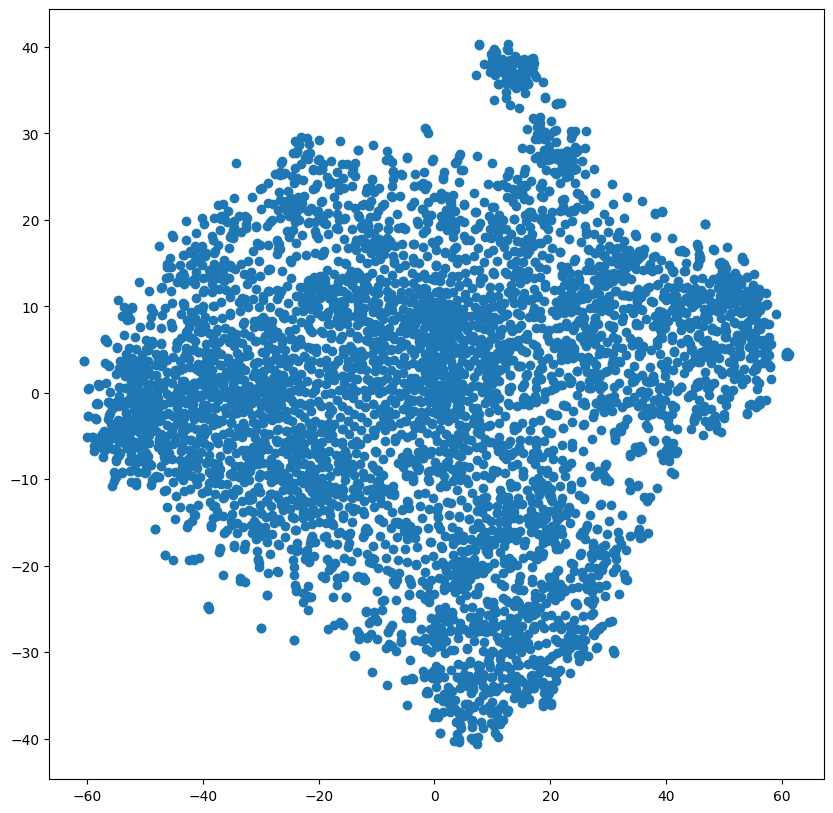

In [63]:
plt.figure(figsize=(10, 10))
plt.scatter(X_reduced.T[0], X_reduced.T[1])
plt.show()

**T:** Now scatterplot the output, but assigning a color (can be random)
depending on the label (remember y_train!). We want any images with the same label to be the same color.

**Q:** Did it really work? How well does the structure reflect the labels? Are the labels clustered or not? Look at the plot and mention some example labels, their colors and their coordinates range on the plot.

> **A:** Yes, it worked. The plot is the same as previously, but now each point is colored based on its label. It seems the colors are mixed together instead of forming more distinct groups. This means the images are not really clustered based on their labels, since points with the same labels are spread through the plot.

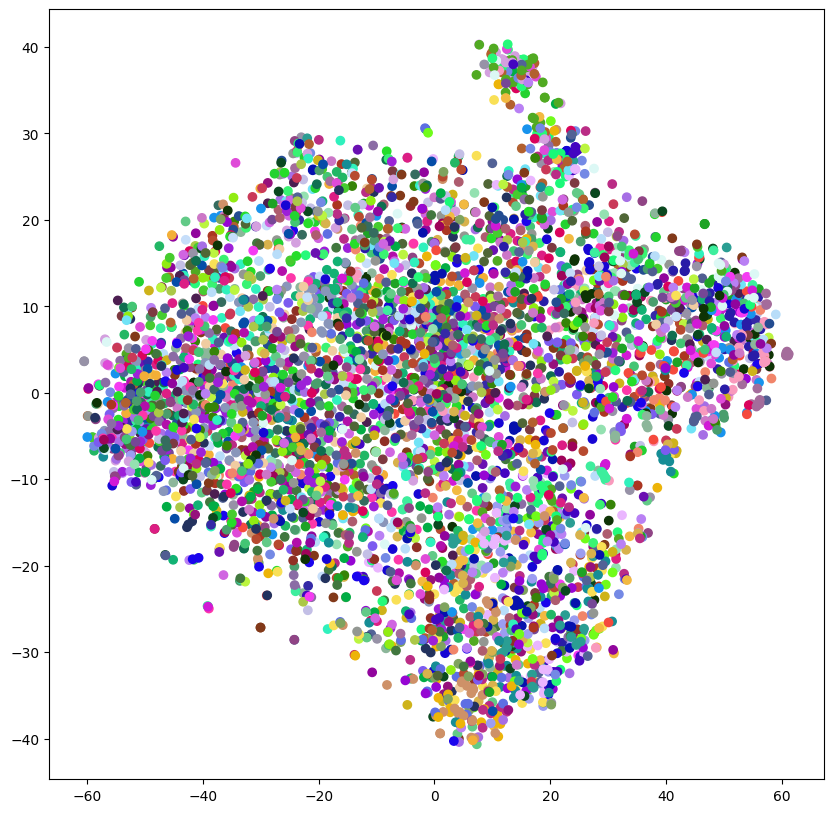

In [64]:
np.random.seed(0)
label_colors = np.random.random((100, 3))
subset_labels = train_labels[:subset_size].flatten()
point_colors = label_colors[subset_labels]

plt.figure(figsize=(10, 10))
plt.scatter(*X_reduced.T, c=point_colors)
plt.show()

## Plotting the images in t-SNE embedding space

**T:** Plot the t-SNE output again --
but now plot the original images at locations given by t-SNE (as we did in class, you should reuse this code!).

> If this gives you problems, ask on Discord. Sometimes it can fail in non-obvious ways, no need to waste time on this.

**Q:** Can you see significant structures now? Any groups of similar images? What specific images can you see, and at what coordinates? In what sense are they 'similar'?

> (Tip: if the generated plot is large, you can click on it and zoom. You can also save the ouput, download the resulting image on your computer
And zoom it more comfortably.)

> **A:** There are more significant structures now. The section at the top of the graph (between 5 and 30 on the x-axis and 25 and 40 on the y-axis) is the most distinct group, as it branches off the rest of the plot. It is made up of mostly blue images, and most of them are underwater with fish or some sort of marine life. There are also clusters of green, orange, black, and objects on a white background that I can see clearly. Overall, the images are grouped based on general color and subject matter.

In [65]:
def plot_image_at_point(im, xy, zoom=1): # from Class 15 Colab
    '''
    Plots a tiny image at point xy.
    '''
    dxy = np.random.rand(2)/100 * plt.ylim()
    plt.arrow(*xy, *dxy)
    ab = AnnotationBbox(OffsetImage(im, zoom=zoom, cmap='gray_r'),
                        xy + dxy, frameon=False)
    plt.gca().add_artist(ab)

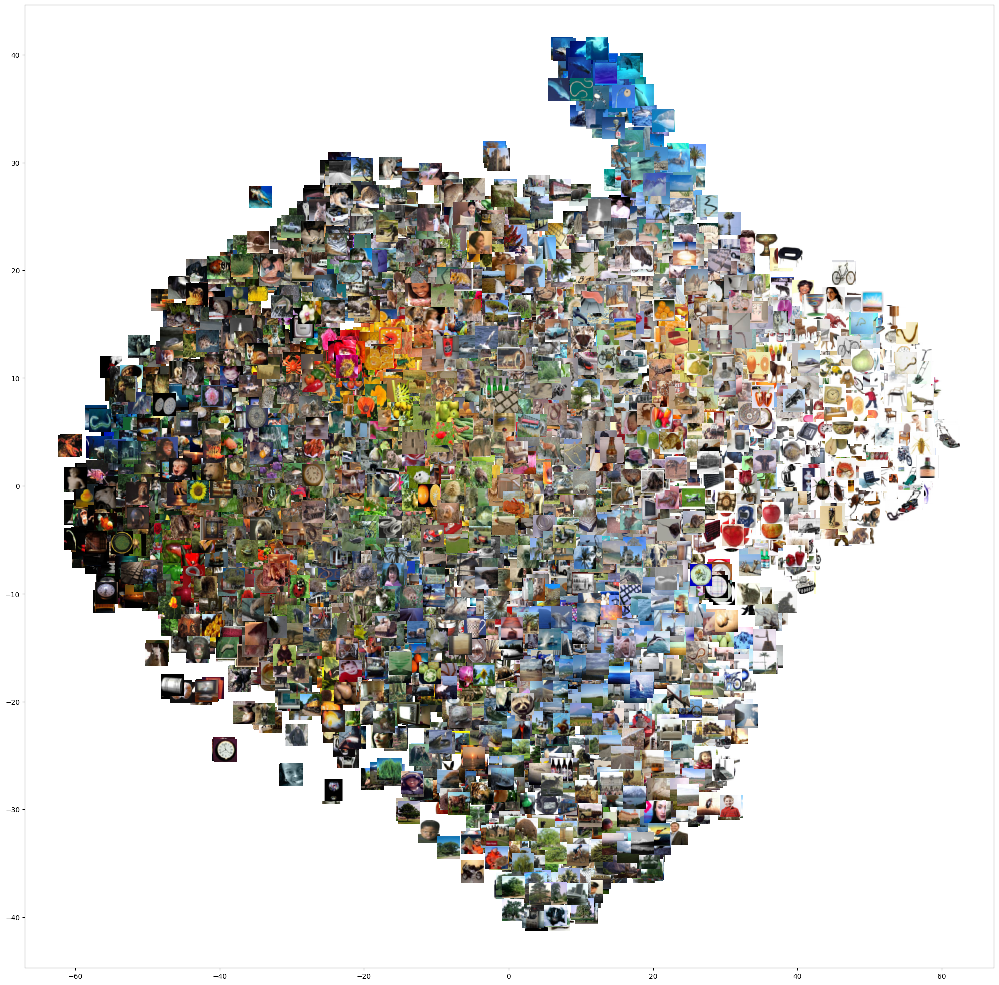

In [66]:
np.random.seed(0)
plt.figure(figsize=(25, 25))
image_zoom = 1.0

plt.scatter(X_reduced.T[0], X_reduced.T[1])

for im, xy in zip(X_subset, X_reduced):
  im_reshaped = im.reshape(32, 32, 3)
  plot_image_at_point(im_reshaped, xy, image_zoom)

## Comparing perplexity values

> As mentioned earlier, the perplexity parameter controls roughly how many neighbours of each vector are taken into account when doing the dimensionality reduction.

**T:** Fit two more t-SNE models on your data using different perplexity values (perhaps one with a much lower perplexity than your original model, and one much higher?). The idea is to also see how tSNE can fail when the perplexity is not set correctly.

**Q:** How did the perplexity parameter affect the structure of the t-SNE output? Mention 3 choices giving vastly different results. Keep the plots.

> Try not to copy paste the code, you can do it in a for loop!

> **A:** The lowest perplexity gives a blob that is less dense, and has much smaller groups of points. This makes sense since lower perplexity focuses on less neighbors and tries to group images that are more locally similar. The highest perplexity 'blob' is very dense, and less apparent groups are clear. The groups that can be seen are larger than in the low and middle perplexity. This is because larger perplexity focuses on more neighbors and looks at more braod similarities between images. The original perplexity is somewhere in between, where it is dense, but also has visible structures and groups of points.


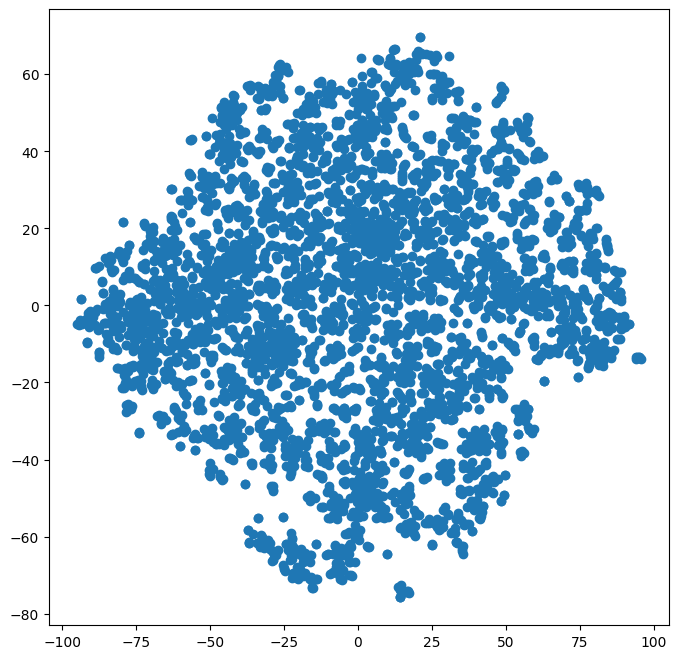

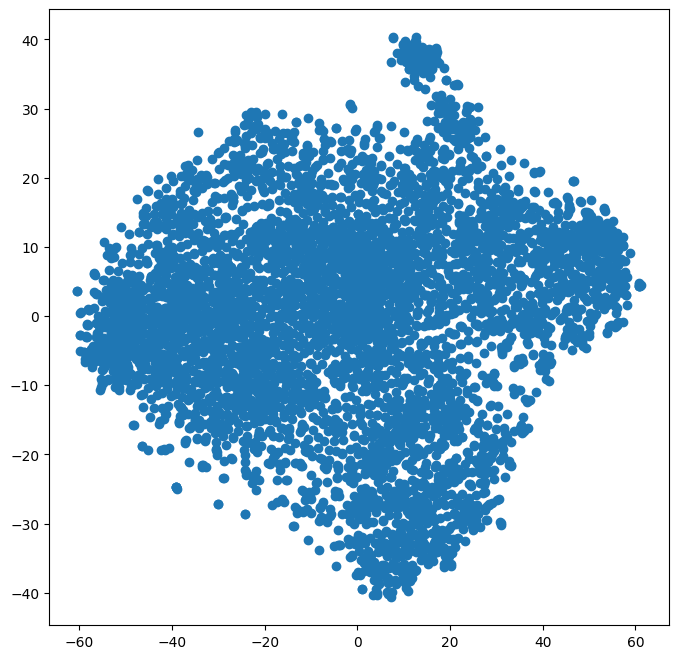

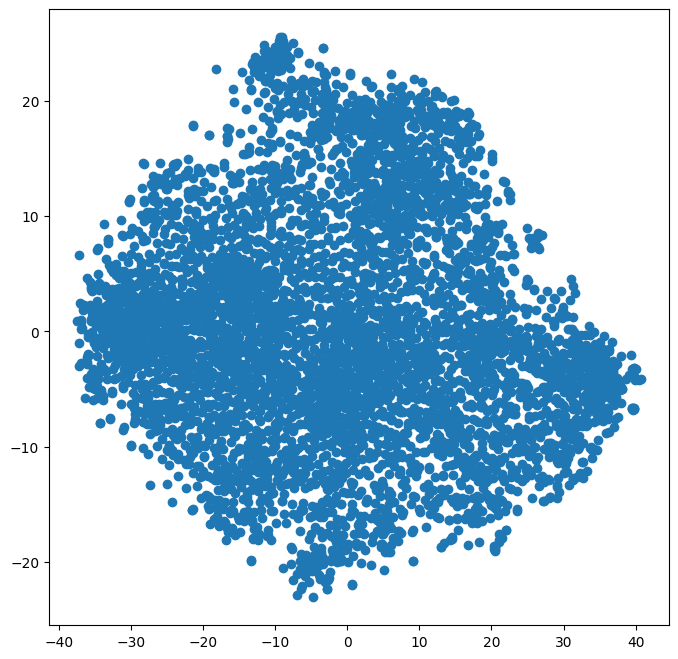

In [67]:
perplexity = [5, 25, 50]

for perp in perplexity:
  tsne = TSNE(n_components=2, max_iter=num_iters,
            perplexity=perp, random_state=my_random_state)
  X_reduced_perp = tsne.fit_transform(X_subset)

  plt.figure(figsize=(8, 8))
  plt.scatter(X_reduced_perp.T[0], X_reduced_perp.T[1])
  plt.show()

## Patterns inside groups of images

> There should be groups of 'similar' images, according to some visible **pattern**. For example, you can see:

> - Images with a centered object on a white background
> - Images with the sky in the upper part and distinct objects in the lower part


**Q:** Find at least 5 new **patterns**, and describe them briefly but concretely (make sure to include the coordinates at which they appear)!

**Important Manual Task:** Once you're happy with your plot, save it to a file (you can take just a screenshot) and **OUTLINE the patterns you noticed in an photo editor** or similar software. Make sure that the axis of the plot are visible. Copy-paste the resulting image in the cell below, like with did in the previous assignment. (It may take a while and it's strange that letters shows up at first, but if you click elsewhere it should work.)

> Imaging you're showing the plot to your (dumb) boss and you need need to mark some things on the tablet for them so that they clearly see what's happening.

> **A:**

> 1. The first pattern is between 5 and 30 on the x-axis and 23 and 43 on the y-axis. The images in this region are primarily blue, and kind of branch off from the rest of the images.

> 2. The second pattern is between 23 and 65 on the x-axis, and -30 and 25 on the y-axis. The images in this region are mostly an object against a white background. These images make up the right edge of the 'blob'.

> 3. The third pattern is between 0 and 30 on the x-axis and -25 and 0 on the y-axis. The images in this region are more grey and blueish.

> 4. The fourth pattern is between -20 and 3 on the x-axis and -8 and 12 on the y-axis. The images in this region are primarily green, and make up a small oval shape in the middle of the image 'blob'.

> 5. The fifth pattern is between -60 and -40 on the x-axis and -25 and 20 on the y-axis. The images in this region are very dark, mostly black and some colors like dark green and red. These images make up the left edge of the 'blob'.

Copy paste the image here!!!

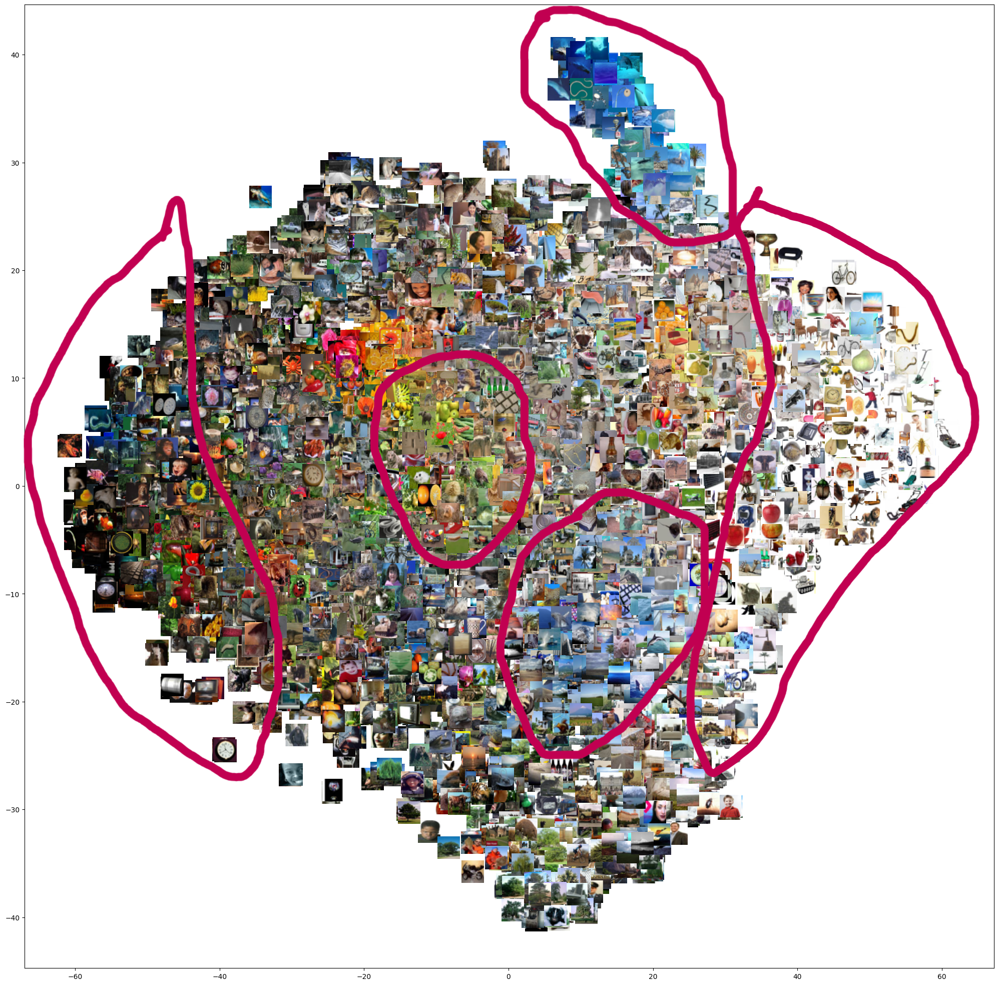

## Important question:

**Q**: *Why* do you think t-SNE picks up these patterns? **This is an important question, so be sure to elaborate!** Refer to the patterns you identified. Your answer should highlight your understanding of t-SNE and related concepts.

> **A:** I think t-SNE picks up on these patterns because it tries to maintain similarities between images when it reduces their dimension to R^2. The images start as vectors in R^3072. t-SNE converts the Euclidian distances between the images into probabilities of how likely two images are to be neighbors and then minimizes the KL divergence make the probability distributions similar. It is looking for similarities in images based on the perplexity and probabilities of the image vectors, and tries to keep the similar images together on the 2D plot, causing patterns to form.

> In the patterns I identified in my plot, this can be seen. In the first pattern, there are mostly blue images, many of which appear to be underwater. The objects in the images are different, but the overall colors and visual charactersistics are similar. Similarly, the second pattern contians mostly dark colored objects against white backgrounds. The third is mostly grey and blue, and is split between keyboards and water based images. The fourth pattern is mostly green, and features a lot of grass. And the fifth is primarily dark colors, like black and dark green, with around half of the pictures being fish in dark water.

> For each of the 5 types of **patterns**
you identified, we can select their
representative images using their t-SNE coordinates.

> Tip: suppose someone would like to perform such a query many, many times. Can you make it efficient for them? Do it in the code.

> For example: in my case "the things on a white background",
had t-SNE coordinates close to $(-15,-15)$, so I found 10 images with t-SNE
coordinates closest to $(-15,-15)$. I then plotted them in one row.

**T:** Do the above for your five selected types of **patterns**.

**Q:** Did you get similar images? Mention similarities and differences you see, be specific.

> **A:** Yes, the images are similar. The images in each row contain colors and often times themes that are similar. For example, the first row has a lot of blue and most of the images are taken underwater, which corresponds with it's section of the patterns from the original plot. Similarly, the fourth row is primarily green and most of the images contain grass, which corresponds with it's region's pattern on the original plot.

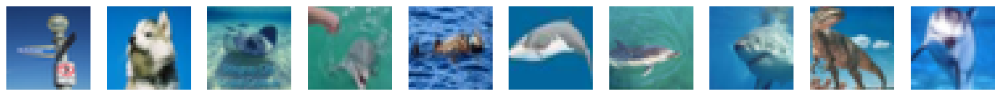

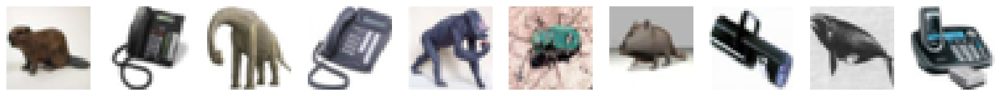

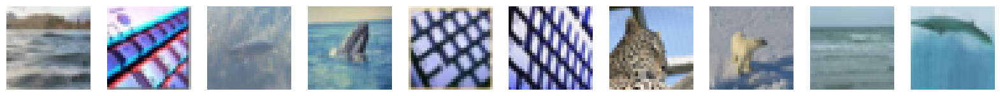

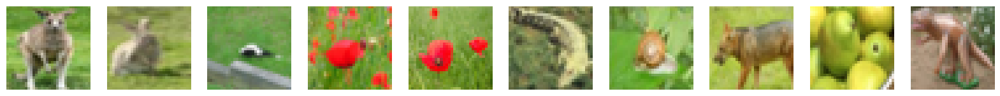

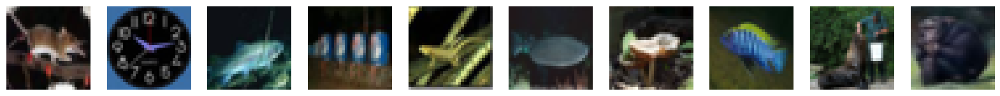

In [68]:
pattern_coords = [
    (15, 33),
    (40, 5),
    (18, -10),
    (-8, 5),
    (-54, 0)
]

for idx, coord in enumerate(pattern_coords):
  target_vector = np.array(coord)
  dists = np.sqrt(np.sum((X_reduced - target_vector) ** 2, axis=1))
  inds = np.argsort(dists)[:10]

  pattern_imgs = [X_subset[i].reshape(32, 32, 3) for i in inds]

  plot_images_in_a_row(pattern_imgs)
  plt.show()


## Back to the high-dimensional space!

> Let's try a similar thing in the original, high-dimensional space.

**T:** Pick a representative image for each of the 5 **patterns**, and find 10 images which are closest *in the original high-dimensional space*. Plot them (in horizontal rows).

## Important question:

**Q**: The results are most likely **not** the same as previously. Do you understand why? **This is really important, elaborate!** Make sure it's clear you know what's happening here.

> **A:** The results are different because in the last task, we were finding the nearest neighbors based on the Euclidean distances in R^2. Now we're finding the nearest neighbors based on the Euclidean distances in R^3072. When t-SNE reduced the images from R^3072 to R^2, it tried to preserve the similarities between the images but not all the original Euclidean distances. Here, we take the same representative images from the 2D plot, but calculate their distances using their image vectors in R^3072. Since t-SNE doesn't preserve all the original distances, the nearest neighbors in R^2 could be different from the nearest neighbors in R^3072.

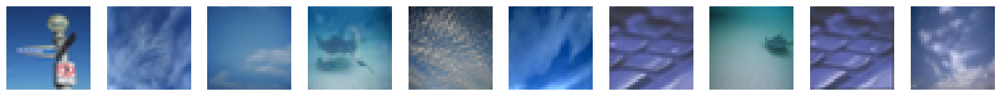

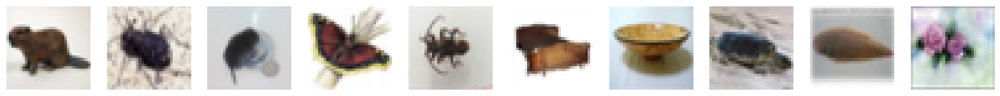

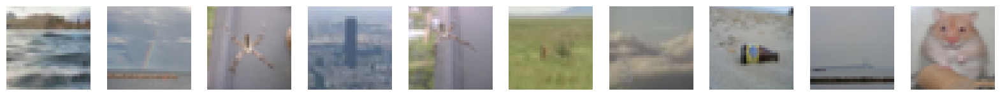

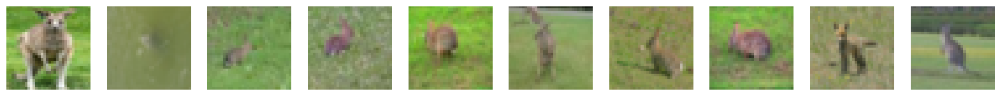

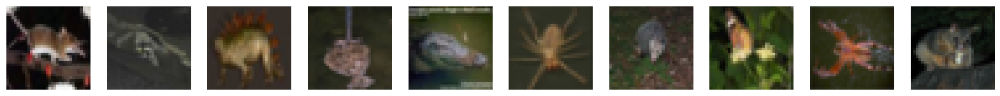

In [69]:
representative_inds = []

for coord in pattern_coords:
  target_vector = np.array(coord)
  dists = np.sqrt(np.sum((X_reduced - target_vector) ** 2, axis=1))
  closest_idx = np.argmin(dists)
  representative_inds.append(closest_idx)

for idx, img_ind in enumerate(representative_inds):
  closest_imgs = nearest_vectors(img_ind, k_nearest=10)
  plot_images_in_a_row(closest_imgs)
  plt.show()

# Actual Data Analysis: Clustering with k-Means

> We can use the insights obtained from the 'exploratory data analysis' performed in the previous part, to preform our data analysis in a reasonable way. In particular, it should give us a hint about a reasonable number of clusters to use.




**Q:** Based on the last part, how many clusters do you think is good for kMeans? Why? Be specific.

> **A:** I think 10 clusters is good for kMeans because it creates enough groups to separate the images with differenct mean colors and characteristics without making too many small clusters. Having less clusters would put too many images in each cluster, and then the images in the clusters wouldn't be as similar. Having more clusters would make many small clusters and could put similar images in different clusters. I think 10 is a good balance for this.  

**T:** Set up KMeans with some rasonable $k$ based on the previous part (no worries: there is no single best answer).

> Tip: to speed things up, import and use **MiniBatchKMeans** instead of KMeans. Browse the documentation to know how it differs. We did not cover this in class, but you can use it.

> In short: MiniBatchKMeans is less accurate, faster, good enough here, and you use it the same way. You don't have to use it -- but not using it will cost you more time and you will lose some credit. So, you know, just use it.

In [70]:
k = 10
kmeans = MiniBatchKMeans(n_clusters=k, random_state=my_random_state, batch_size=1000, n_init='auto')

**T:** Fit kMeans with your data.

In [71]:
kmeans.fit(X_subset)

MiniBatchKMeans(batch_size=1000, n_clusters=10, random_state=1236)

## Plot t-SNE embedding using clusters' labels

> Let's see to what extent the kMeans clusters
resemble the structure of the t-SNE output.

**T:** Plot the t-SNE embedding again -- but this time assign
colors corresponding to the kMeans cluster of each image.

**Q:** Can you see significant groups of points with the same color (label)? (If not, something is wrong.) How many do you see, roughly? Describe them, mention the rough position (x,y) and some characteristic features for some of them.

> **A:** I see around 10 groups of colors, which makes sense since K-means was set to 10 clusters. There is a group of yellow points on the right edge of the 'blob' at around (50, 10). The left side has a blue-green group of points at around (-50, 0). The top of the 'blob' has a small group of purple points branching off at around (15, 35). The rest are grouped inside the blob.


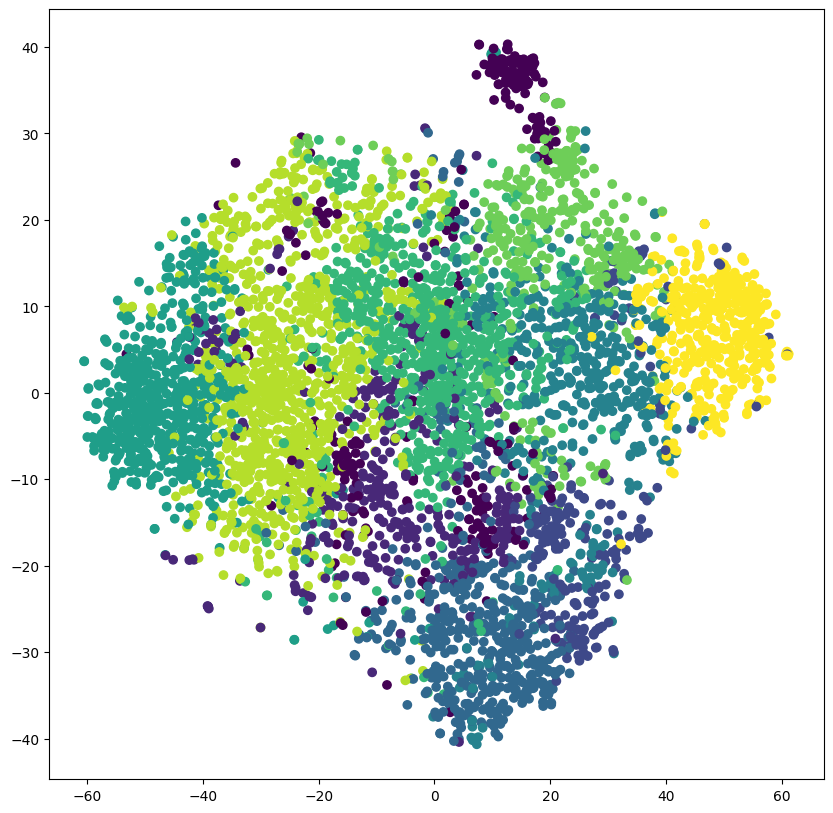

In [72]:
cluster_labels = kmeans.labels_

plt.figure(figsize=(10, 10))
plt.scatter(X_reduced.T[0], X_reduced.T[1], c=cluster_labels)
plt.show()

**T:** Repeat the plot above but **define the color of each point as the (approximate) mean color of
the images in the cluster** to which the image belongs to.

> Hint: try to find a simple way of getting these colors (avoid complicated computations).

> You should see some blue and orange parts. Also some almost white and quite dark parts? If yes -- good. **When in doubt, it's okay to post this particular image on discord and ask!**

> If you don't see them -- something is likely wrong. Maybe too few iterations? If everything is gray, something is very  wrong -- maybe way too few clusters (k). Tune the parameters until happy. Do you see why we wanted to use the faster, approximate version of k-means? Data analysis is often done iteratively/interactively -- so efficient algorithms save your time.

**Q**: Describe 5 features you see on the plot, along with their tSNE coordinates.

> **A:** One feature is around (50, 10) and is primarily light greyish/ivory colored points. Another is around (15, 38) and consists mostly of blue points. The third is located around (10, -39) and is mostly grey points, with a few brown mixed in. There is a group of dark brown points around (-50, 0). Next to the dark brown points there is a group of slightly lighter brown points at around (-25, 0).

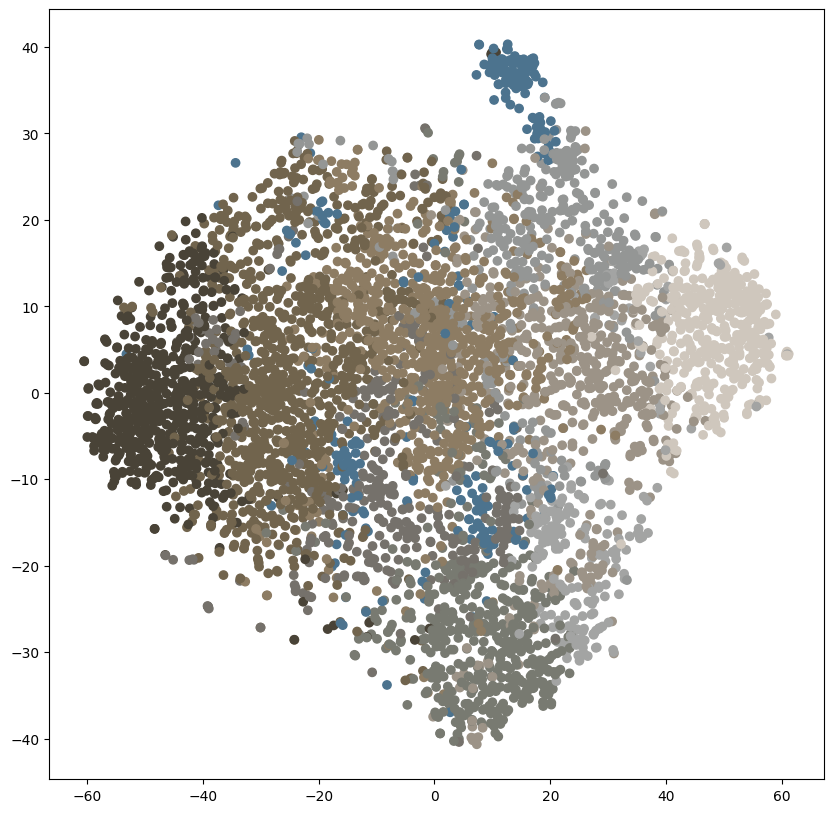

In [73]:
mean_colors = []

for i in range(k):
  cluster_images = X_subset[cluster_labels == i].reshape(-1, 32, 32, 3)
  mean_color = cluster_images.mean(axis=(0, 1, 2))
  mean_colors.append(mean_color)

mean_colors = np.array(mean_colors)
point_colors = mean_colors[cluster_labels]

plt.figure(figsize=(10, 10))
plt.scatter(X_reduced.T[0], X_reduced.T[1], c=point_colors)
plt.show()

## Data Analysis on the entire dataset

> If you're not satisfied with the quality, you can tune the parameters some more.

**T:** If everything looks acceptable, rerun the final data analysis on the full dataset.

In [74]:
kmeans.fit(train_images_reshaped)

MiniBatchKMeans(batch_size=1000, n_clusters=10, random_state=1236)

> Let's verify if the clusters we got on the entire dataset are reasonable.

**T:** For each cluster center, plot, say, 10 images which are closest in the sense of the Euclidean metric to it. Also plot the cluster center!

**Q:** Looks good? Or maybe you see something suspicious? Describe some examples.

> For example: if any cluster center look like a single image in the dataset, you likely chose too many clusters!

> **A:** The images in each row share characteristics. They have the same color schemes for the most part, and depict the same kinds of things. For example, the images in the first row are mainly some kind of animal or bug on a sand colored backround.The seventh row is made up of lightly colored images and many of them have pastel colored circular objects in the center like clocks or plates. The eighth row is made up of light colored landscapes. The cluster centers look like a mixture of all the images, which makes sense because they represent the average of all the images in each cluster.

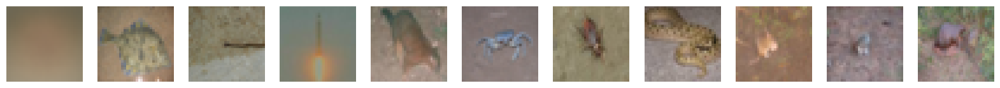

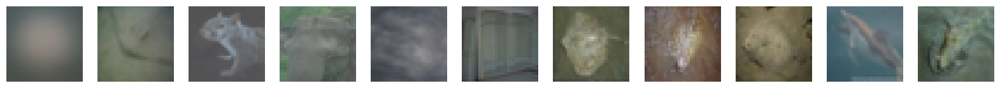

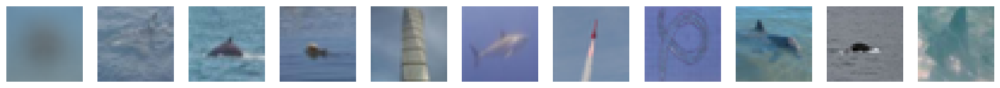

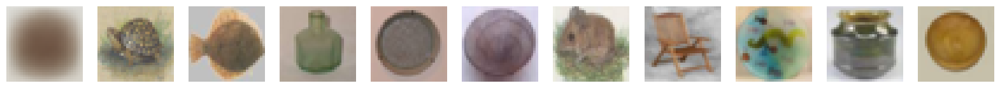

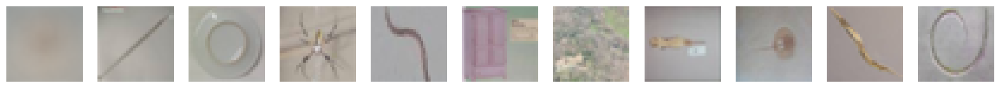

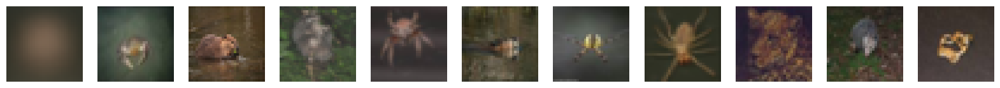

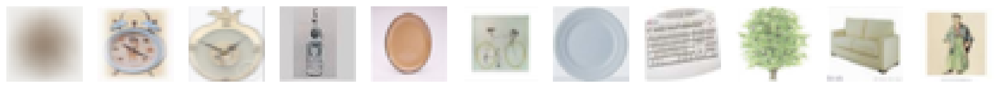

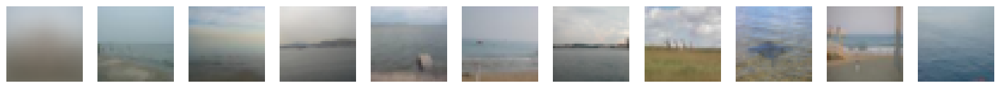

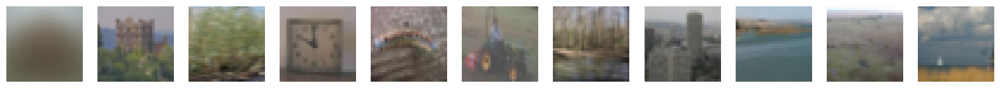

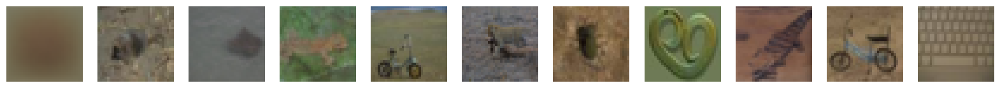

In [75]:
for i in range(k):
  center = kmeans.cluster_centers_[i]
  distances = np.sqrt(np.sum((train_images_reshaped - center) ** 2, axis=1))
  sorted_inds = np.argsort(distances)
  k_inds = sorted_inds[:10]

  center_reshaped = center.reshape(32, 32, 3)
  closest_imgs = [train_images_reshaped[idx].reshape(32, 32, 3) for idx in k_inds]

  plot_images_in_a_row([center_reshaped] + closest_imgs)
  plt.show()

# Bonus \#1 [some extra credit]:

Try your own image! Does it belong to a cluster you'd expect? What do you see?

In [76]:
from google.colab import files
from PIL import Image

def get_uploaded_image(size = (32,32)):
  '''Lets you download and image.
  Returns an np.array representing the downloaded image.
  The image is resized to the provided size.
  '''
  filename = list(files.upload())[-1]
  im = Image.open(filename).resize(size)
  npim = np.array(im)[..., :3].astype(float)
  if npim.max() > 2:
    npim /= 255.
  return npim

Saving coca-cola-glass-bottle2025.jpg to coca-cola-glass-bottle2025 (1).jpg


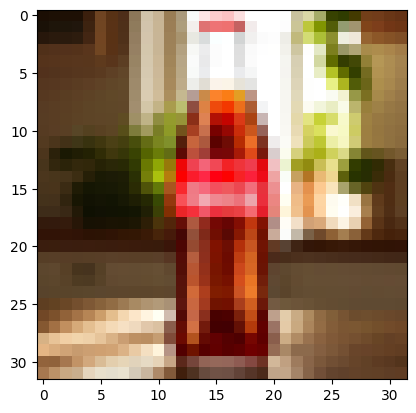

In [77]:
your_image = get_uploaded_image()
plt.imshow(your_image)

**T:** Plot the 'most similar' images to the cluster closest to the image. (Hint: You can do this on your own, but Kmeans has a function called 'predict' which returns the index of the closest cluster center.)

**T:** Plot the 'most similar' images to your image.

**Q:** Is there any advantage to finding the 'most similar' images via the clusters? What are the benefits? What do we lose? How is this tradeoff affected by the number of clusters? Please elaborate!

> **A:** I think the 'most similar' images that came from directly comparing to the original image are more similar to it than the images from the clusters. I think this makes sense since the cluster method compares the images to the cluster center rather than the original image. The advantage of using clusters is that it can help find groups of images with similar characteristics, but the disadvantage is that the images that are closest to the cluster center might not be the most similar to the original image. If there are less clusters, there will be more images in each cluster, and it would be less likely to miss similar images. If there are more clusters, there will be less images in each cluster, and this limits the amount of images that are the most similar to the original as they could be in other clusters.

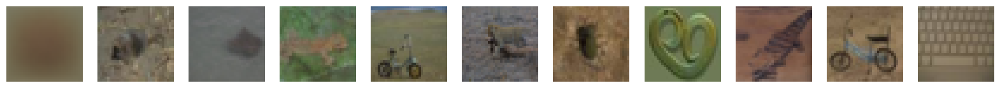

In [78]:
your_image = your_image.astype('float32') # was stored as float64 but needs to be float32
cluster_ind = kmeans.predict(your_image.reshape(1, -1))[0]

center = kmeans.cluster_centers_[cluster_ind]
distances = np.sqrt(np.sum((train_images_reshaped - center) ** 2, axis=1))
sorted_inds = np.argsort(distances)
k_inds = sorted_inds[:10]

center_reshaped = center.reshape(32, 32, 3)
closest_imgs = [train_images_reshaped[idx].reshape(32, 32, 3) for idx in k_inds]


plot_images_in_a_row([center_reshaped] + closest_imgs)
plt.show()


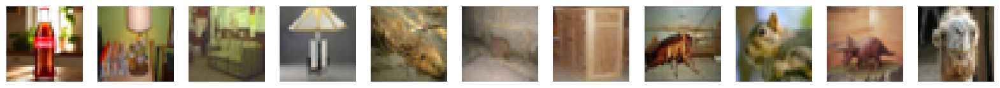

In [79]:
your_vector = your_image.reshape(1, -1)

distances = np.sqrt(np.sum((train_images_reshaped - your_vector) ** 2, axis=1))
sorted_inds = np.argsort(distances)
k_inds = sorted_inds[:10]

similar_imgs = [train_images[idx] for idx in k_inds]

plot_images_in_a_row([your_image] + similar_imgs)
plt.show()